In [1]:
from mltools.matching.render import MeshRenderer
from mltools.matching.utils import MeshroomCamerasParser
import numpy as np

cameras_path = "../../data/matching/cameras/cameras_v2.sfm"
obj_path = "../../data/matching/textured_mesh_v2/texturedMesh.obj"
# obj_path = "../../data/matching/meshroom/downsampled.obj"

cameras = MeshroomCamerasParser(cameras_path).parse()

# Initialize the renderer once
renderer = MeshRenderer(obj_path, default_width=1024, default_height=682)

Undistorted FBO size: 1092x727 for requested 1024x682
Trimming pixel array from 1092x727 to 1024x682 with padding (34, 22)
Unique positions for visualization: 632049
Depth range for visualization: min=0.2442600131034851, max=0.4884231388568878


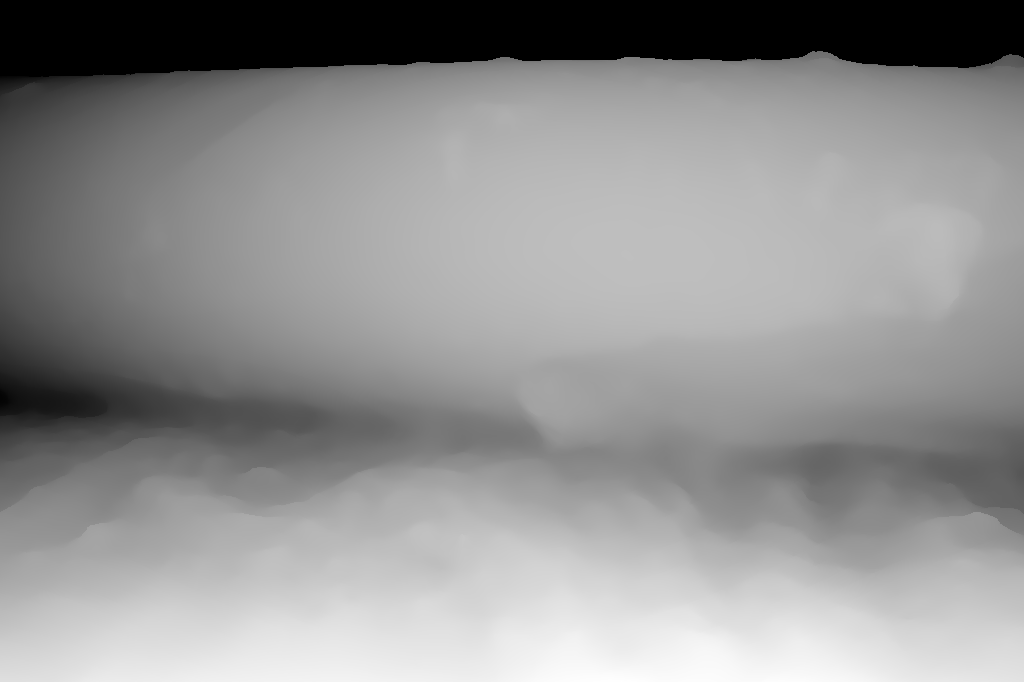

In [2]:
image_id = "2041"
camera = cameras[image_id]
camera_cpy = camera.copy()
#camera_cpy['distortion_params'] = np.zeros(3)
#camera_cpy['cx'] = 0.5 * camera['cx']
#camera_cpy['cy'] = 0.5 * camera['cy']
image = renderer.visualize_depth(camera_cpy)
display(image)

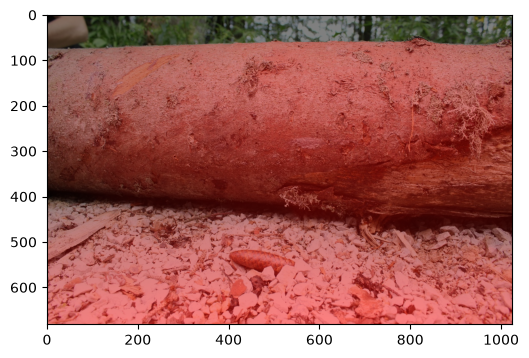

In [3]:
images_dir = "../../data/matching/resized_1024"
from matplotlib import pyplot as plt

# overlay the depth map on the original image
original_image_path = f"{images_dir}/{image_id}.JPG"
original_image = plt.imread(original_image_path)
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
# overlay as red with some transparency
red_image = np.array(image)
red_image[:,:,1:3] = 0
plt.imshow(red_image, alpha=0.5)
plt.show()

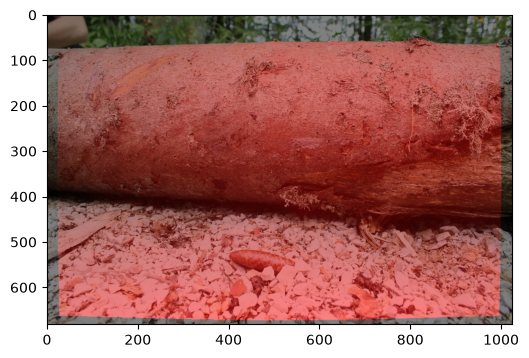

In [3]:
images_dir = "../../data/matching/resized_1024"
from matplotlib import pyplot as plt

# overlay the depth map on the original image
original_image_path = f"{images_dir}/{image_id}.JPG"
original_image = plt.imread(original_image_path)
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
# overlay as red with some transparency
red_image = np.array(image)
red_image[:,:,1:3] = 0
plt.imshow(red_image, alpha=0.5)
plt.show()

In [ ]:
pixel_data = renderer.render(camera)

In [17]:
pixel_data.shape

(682, 1024, 4)

In [38]:
data = pixel_data.reshape(-1, 4)
print(data.shape)
print(f"Unique depth values: {np.unique(data[:, 3])}")
data = data[data[:, 3] > 0.5, :3]  # Filter out invalid pixels based on alpha channel
data.shape

(698368, 4)
Unique depth values: [0. 1.]


(631803, 3)

In [33]:
np.unique(data[:, 2])

array([0.        , 0.00392157, 0.00784314, 0.01176471, 0.01568628,
       0.01960784, 0.02352941, 0.02745098, 0.03137255, 0.03529412,
       0.03921569, 0.04313726, 0.04705883, 0.0509804 , 0.05490196],
      dtype=float32)